In [5]:
import os
from dotenv import load_dotenv
load_dotenv(override=True)

os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

In [11]:
from langchain_openai import ChatOpenAI

llm = ChatOpenAI(model="gpt-4o-mini")

llm.invoke("hi")

AIMessage(content='Hello! How can I assist you today?', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 9, 'prompt_tokens': 8, 'total_tokens': 17, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_20eb127183', 'id': 'chatcmpl-El7Wc0rRbj5Vs01c9b8elvTygQJID', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a1e851-fff9-7282-a511-1b21190a9d46-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 8, 'output_tokens': 9, 'total_tokens': 17, 'input_token_details': {'audio': 0, 'cache_read': 0}, 'output_token_details': {'audio': 0, 'reasoning': 0}})

# **PYDANTIC GRAPH**

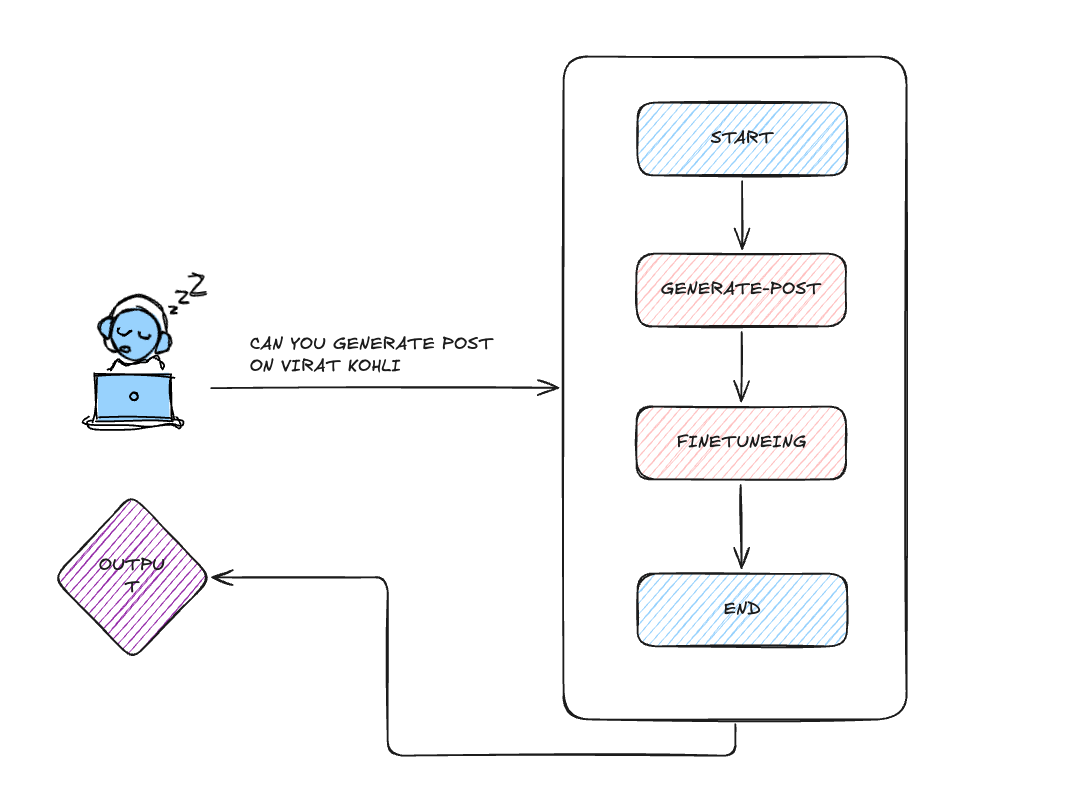

## **CREATING THE SCHEAMA**

In [7]:
from pydantic import BaseModel, Field

class graph_schema(BaseModel):
    topic: str = Field(description="the topic about graph")
    post: str = Field(description="the instagram post content")
    fine_tune: str = Field(description="the fine tuned instagram post content")

In [8]:
demo_obj = graph_schema(
    topic = "the importance of love",
    post = "its about love of ai",
    fine_tune = "Ai is next companion",
)

In [9]:
demo_obj

graph_schema(topic='the importance of love', post='its about love of ai', fine_tune='Ai is next companion')

## **Generating the nodes**

In [12]:
# this node is about generating the content
def generate_post(state: graph_schema) -> graph_schema:

    # converting the pydantic model into dictionary

    state = state.model_dump()

    # Extracting the topic from state

    topic = state['topic']

    post = llm.invoke(f"Write a post in instagram about {topic}").content

    state['post'] = post

    return state


# this node is about finetuning the content
def finetune_post(state: graph_schema) -> graph_schema:

    # converting the pydantic model into dictionary

    state = state.model_dump()

    # Extracting the topic from state

    post = state['post']

    fine_tune_post = llm.invoke(f"what ever the post generated fom generatepost about  {post} finetune everything give genz tone").content

    state['fine_tune'] = fine_tune_post

    return state

In [14]:
from langgraph.graph import StateGraph,START,END

graph = StateGraph(graph_schema)

## we need to register the nodes
graph.add_node("generate_post",generate_post)
graph.add_node("finetune_post",finetune_post)


## we need connect via edges

graph.add_edge(START,"generate_post")
graph.add_edge("generate_post","finetune_post")
graph.add_edge("finetune_post",END)

pydantic_graph = graph.compile()

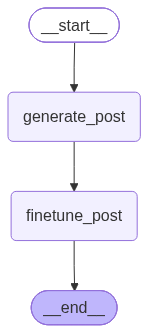

In [15]:
from IPython.display import Image, display

Image(pydantic_graph.get_graph().draw_mermaid_png())

In [16]:
pydantic_graph.invoke(
    {
        "topic":"write story about karnataka",
        "post":"",
        "fine_tune" : ""
    }
)

{'topic': 'write story about karnataka',
 'post': "🌟✨ Discover the Heart of Karnataka! 🌿📜\n\nHey Explorers! 🌍💕 Today, I’m taking a moment to celebrate the incredible stories and vibrant culture of Karnataka, one of India's most enchanting states! From the lush hills of Coorg to the historic ruins of Hampi, there’s so much to uncover! 🏞️🏰\n\n🏄\u200d♂️ Whether you’re seeking adventure, indulging in delicious food, or soaking in the rich heritage, Karnataka has something for everyone. From the aromatic filter coffee ☕️ to the delectable Mysore Pak, your taste buds are in for a treat!\n\n📸 Swipe left to explore breathtaking landscapes, majestic palaces, and the warm smiles of the locals who make this place special! Let each photo inspire you to write your own story. Have you been to Karnataka? What was your favorite experience? Share your stories in the comments below! 💬👇\n\n#Karnataka #IncredibleIndia #TravelDiaries #FollowYourHeart #CulturalJourney #StoryTelling #ExploreIndia #InstaTrave

In [17]:
pydantic_graph.invoke(
    {
        "topic":126328643,
        "post":"",
        "fine_tune" : ""
    }
)

ValidationError: 1 validation error for graph_schema
topic
  Input should be a valid string [type=string_type, input_value=126328643, input_type=int]
    For further information visit https://errors.pydantic.dev/2.13/v/string_type